---
# Mentor Presentation — Dataset Preparation Summary

The cells below are **read-only reporting** — nothing is re-downloaded or rewritten.
They assume the following files already exist (produced by the download & sanity-check notebooks):
- `annotations/segments.csv`
- `annotations/segments_available.csv`
- `annotations/download_report.csv`

Paste these cells **after the Setup cell** in `02_youcook2_sanity_check.ipynb`.


## P1 · Core Data Inventory
High-level counts: videos, segments, and train/val split.

In [4]:
import os, json, pandas as pd

with open('/home/ubuntu/youcook2-videos/paths.json') as f:
    PATHS = json.load(f)

ANN_DIR = PATHS['annotations']

df_all   = pd.read_csv(os.path.join(ANN_DIR, 'segments.csv'))
df_avail = pd.read_csv(os.path.join(ANN_DIR, 'segments_available.csv'))
report   = pd.read_csv(os.path.join(ANN_DIR, 'download_report.csv'))

print("=" * 55)
print("  CORE DATA INVENTORY")
print("=" * 55)

print("\n── Full annotation set (all videos) ──")
print(f"  Total segments       : {len(df_all):,}")
print(f"  Unique videos        : {df_all['video_id'].nunique():,}")
print(f"  Training segments    : {(df_all['subset']=='training').sum():,}")
print(f"  Validation segments  : {(df_all['subset']=='validation').sum():,}")

print("\n── Available (successfully downloaded) ──")
print(f"  Segments available   : {len(df_avail):,}  ({100*len(df_avail)/len(df_all):.1f}% of total)")
print(f"  Videos available     : {df_avail['video_id'].nunique():,}")
print(f"  Training segments    : {(df_avail['subset']=='training').sum():,}")
print(f"  Validation segments  : {(df_avail['subset']=='validation').sum():,}")

print("\n── Per-video segment count (available set) ──")
segs_per_video = df_avail.groupby('video_id').size()
print(f"  Mean segments/video  : {segs_per_video.mean():.1f}")
print(f"  Min                  : {segs_per_video.min()}")
print(f"  Max                  : {segs_per_video.max()}")
print(f"  Median               : {segs_per_video.median():.1f}")

print("\n── Sample rows ──")
display(df_avail[['video_id','subset','recipe_type','segment_id','start_sec','end_sec','duration','caption']].head(5))


  CORE DATA INVENTORY

── Full annotation set (all videos) ──
  Total segments       : 13,829
  Unique videos        : 1,790
  Training segments    : 10,337
  Validation segments  : 3,492

── Available (successfully downloaded) ──
  Segments available   : 13,716  (99.2% of total)
  Videos available     : 1,774
  Training segments    : 10,259
  Validation segments  : 3,457

── Per-video segment count (available set) ──
  Mean segments/video  : 7.7
  Min                  : 3
  Max                  : 16
  Median               : 7.0

── Sample rows ──


,video_id,subset,recipe_type,segment_id,start_sec,end_sec,duration,caption
0,GLd3aX16zBg,training,113,GLd3aX16zBg_000,90.0,102.0,12.0,spread margarine on two slices of white bread
1,GLd3aX16zBg,training,113,GLd3aX16zBg_001,114.0,127.0,13.0,place a slice of cheese on the bread
2,GLd3aX16zBg,training,113,GLd3aX16zBg_002,132.0,138.0,6.0,place the bread slices on top of each other an...
3,GLd3aX16zBg,training,113,GLd3aX16zBg_003,139.0,145.0,6.0,flip the sandwich over and press down
4,GLd3aX16zBg,training,113,GLd3aX16zBg_004,173.0,174.0,1.0,cut the sandwich in half diagonally


## P2 · Download Health
Shows what fraction of the original dataset survived (deletions, private videos, etc.).

In [7]:
import os

VIDEO_DIR = '/home/ubuntu/youcook2-videos/videos'
mp4_files = [f for f in os.listdir(VIDEO_DIR) if f.endswith('.mp4')]
print(f"MP4 files on disk: {len(mp4_files)}")
print("Sample:", mp4_files[:5])

MP4 files on disk: 1959
Sample: ['EzGGJLGgSl8.mp4', 'aMtZQgH_MRc.mp4', '8X2wDyjl6T8.mp4', 'RV0_DWkbjx8.mp4', 'LDig6UT8uWw.mp4']


In [2]:
import os, pandas as pd

VIDEO_DIR = '/home/ubuntu/youcook2-videos/videos'
ANN_DIR   = '/home/ubuntu/youcook2-videos/annotations'

# Build report purely from disk
mp4_files = {f.replace('.mp4', '') for f in os.listdir(VIDEO_DIR) if f.endswith('.mp4')}

df_all   = pd.read_csv(os.path.join(ANN_DIR, 'segments.csv'))
all_vids = df_all['video_id'].unique()

report = pd.DataFrame({
    'video_id': all_vids,
    'status':   ['success' if vid in mp4_files else 'failed' for vid in all_vids]
})

# Save it so you don't need to regenerate it again
report.to_csv(os.path.join(ANN_DIR, 'download_report.csv'), index=False)

# Rebuild df_avail
df_avail = df_all[df_all['video_id'].isin(mp4_files)].copy().reset_index(drop=True)

print(f"Videos on disk       : {len(mp4_files):,}")
print(f"Status success       : {(report['status']=='success').sum():,}")
print(f"Status failed        : {(report['status']=='failed').sum():,}")
print(f"Available segments   : {len(df_avail):,}")

Videos on disk       : 1,959
Status success       : 1,774
Status failed        : 16
Available segments   : 13,716


In [8]:
import os, pandas as pd

VIDEO_DIR = '/home/ubuntu/youcook2-videos/videos'
ANN_DIR   = '/home/ubuntu/youcook2-videos/annotations'

# Rebuild report from disk
mp4_files  = {f.replace('.mp4', '') for f in os.listdir(VIDEO_DIR) if f.endswith('.mp4')}
report     = pd.read_csv(os.path.join(ANN_DIR, 'download_report.csv'))

# Override status based on what's actually on disk
report['status'] = report['video_id'].apply(
    lambda vid: 'success' if vid in mp4_files else 'failed'
)

print(report['status'].value_counts())

status
success    1774
failed       16
Name: count, dtype: int64


## P3 · Segment Duration Distribution
Shows the spread of clip lengths — directly informs frame-sampling decisions downstream.

  SEGMENT DURATION STATISTICS (available set)
  count       : 13716.00s
  mean        : 19.62s
  std         : 18.29s
  min         : 1.00s
  5%          : 3.00s
  25%         : 8.00s
  50%         : 14.00s
  75%         : 25.00s
  95%         : 54.00s
  max         : 264.00s

  Segments < 5s   : 1,339  — may yield very few frames
  Segments > 60s  : 483  — memory consideration for batch loading


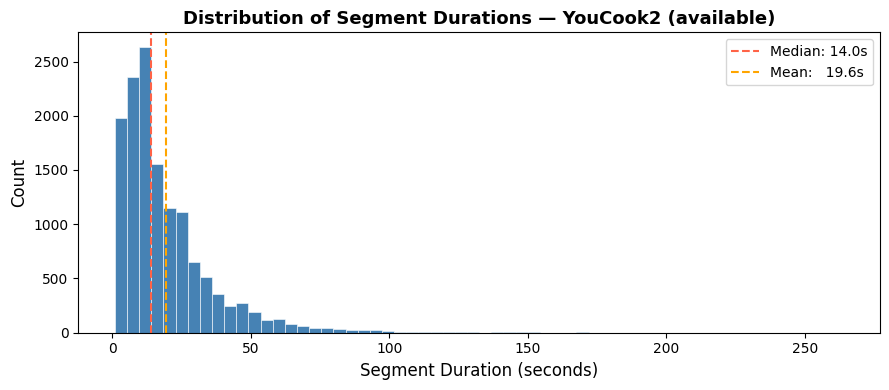

In [10]:
import matplotlib.pyplot as plt
import numpy as np

print("=" * 55)
print("  SEGMENT DURATION STATISTICS (available set)")
print("=" * 55)
stats = df_avail['duration'].describe(percentiles=[.05, .25, .5, .75, .95])
for label, val in stats.items():
    print(f"  {label:<12}: {val:.2f}s")

short = (df_avail['duration'] < 5).sum()
long  = (df_avail['duration'] > 60).sum()
print(f"\n  Segments < 5s   : {short:,}  — may yield very few frames")
print(f"  Segments > 60s  : {long:,}  — memory consideration for batch loading")

# Histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df_avail['duration'], bins=60, color='steelblue', edgecolor='white', linewidth=0.4)
ax.axvline(df_avail['duration'].median(), color='tomato', linestyle='--', label=f"Median: {df_avail['duration'].median():.1f}s")
ax.axvline(df_avail['duration'].mean(),   color='orange', linestyle='--', label=f"Mean:   {df_avail['duration'].mean():.1f}s")
ax.set_xlabel('Segment Duration (seconds)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Distribution of Segment Durations — YouCook2 (available)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


## P4 · Recipe Type Distribution
Shows domain diversity across dish categories — motivates class-imbalance awareness.

  RECIPE TYPE DISTRIBUTION (available set)
  Unique recipe types : 89

recipe_type
419    215
203    209
221    198
302    197
103    194
209    194
401    192
416    192
214    191
319    189
229    189
121    189
212    186
110    186
201    184
223    184
406    182
409    181
117    181
119    181
208    181
122    180
127    175
204    175
210    173
305    170
303    170
323    168
206    167
325    166
421    166
404    166
418    165
405    164
116    163
314    163
425    162
309    162
218    162
207    160
222    159
101    159
308    158
213    158
318    157
403    157
124    156
215    154
115    154
412    152
413    149
114    148
202    145
126    145
211    145
106    144
112    144
108    142
301    142
102    141
324    140
226    139
225    139
230    139
107    137
205    137
105    136
307    136
317    133
227    132
410    131
113    130
228    130
321    128
109    128
111    127
316    126
224    124
219    123
104    118
422    116
120    115
304    113
306 

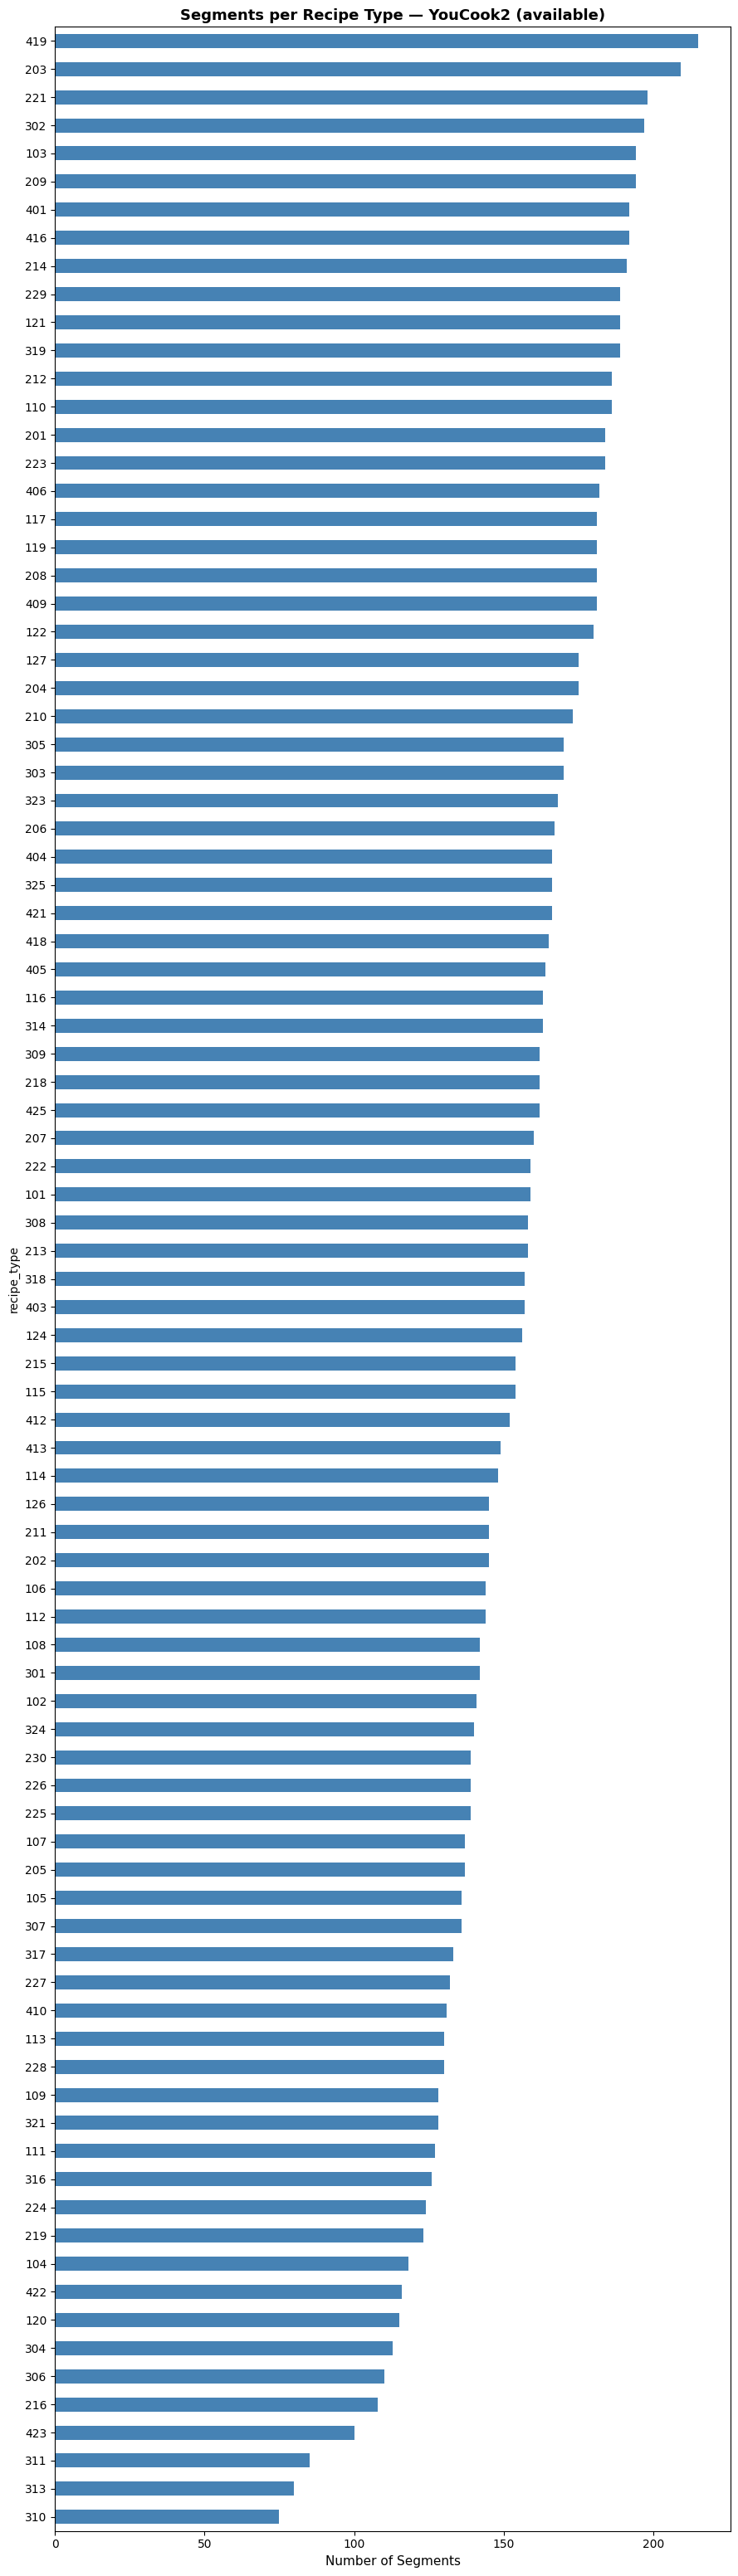

In [11]:
import matplotlib.pyplot as plt

print("=" * 55)
print("  RECIPE TYPE DISTRIBUTION (available set)")
print("=" * 55)

recipe_counts = df_avail['recipe_type'].value_counts()
print(f"  Unique recipe types : {len(recipe_counts)}")
print()
print(recipe_counts.to_string())

# Horizontal bar chart (easier to read with many categories)
fig, ax = plt.subplots(figsize=(9, max(4, len(recipe_counts) * 0.35)))
recipe_counts.sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Number of Segments', fontsize=11)
ax.set_title('Segments per Recipe Type — YouCook2 (available)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## P5 · Per-Video Segment Table
Complete listing of all available videos with segment count, duration stats, and caption preview — the main artefact for your mentor.

In [12]:
import pandas as pd

# Build per-video summary
video_summary = (
    df_avail
    .groupby(['video_id', 'subset', 'recipe_type'])
    .agg(
        n_segments   = ('segment_id',  'count'),
        total_dur_s  = ('duration',    'sum'),
        min_start    = ('start_sec',   'min'),
        max_end      = ('end_sec',     'max'),
        sample_caption = ('caption',   'first'),
    )
    .reset_index()
    .sort_values(['subset', 'recipe_type', 'video_id'])
    .reset_index(drop=True)
)

video_summary['total_dur_s'] = video_summary['total_dur_s'].round(1)
video_summary['sample_caption'] = video_summary['sample_caption'].str[:60] + '...'

print(f"Total available videos: {len(video_summary):,}")
print()
print("First 20 rows (sorted by subset → recipe → video_id):")
display(video_summary.head(20))

# Optionally save the full table
out_path = os.path.join(ANN_DIR, 'per_video_summary.csv')
video_summary.to_csv(out_path, index=False)
print(f"\nFull table saved → {out_path}")


Total available videos: 1,774

First 20 rows (sorted by subset → recipe → video_id):


,video_id,subset,recipe_type,n_segments,total_dur_s,min_start,max_end,sample_caption
0,0O4bxhpFX9o,training,101,5,102.0,41.0,195.0,place the bacon slices on a baking pan and coo...
1,17v08qtr8UM,training,101,6,37.0,42.0,102.0,cook the bacon on the pan...
2,2Ihlw5FFrx4,training,101,7,93.0,40.0,159.0,spread feta cream cheese onto a slice of bread...
3,3rtzSsuJ4Ng,training,101,5,106.0,40.0,158.0,add egg yolk dijon mustard anchovies garlic mi...
4,M5TwnzHdT2Q,training,101,6,93.0,25.0,139.0,fry bacon on a pan...
5,QWhn9Ncvvso,training,101,7,163.0,24.0,210.0,take baked bacon slices on a plate...
6,S7hpTy1Rx1k,training,101,6,122.0,30.0,158.0,cut onions into thin slices...
7,VcIF3HOI9wI,training,101,9,134.0,62.0,235.0,take 2 strips of bacon and cut each into 2 pie...
8,bQ3QYyFglc0,training,101,11,96.0,14.0,163.0,cook the bacon in a pan...
9,fOPF3x6c2WI,training,101,6,39.0,11.0,76.0,prepare a pair of buns...



Full table saved → /home/ubuntu/youcook2-videos/annotations/per_video_summary.csv


## P6 · All Segments for a Single Video
Drills into one video to show the caption + timestamp structure your mentor will want to see.

In [13]:
# Change VIDEO_ID to any video you want to show your mentor
# or leave as None to auto-pick the video with the most segments
VIDEO_ID = None

if VIDEO_ID is None:
    VIDEO_ID = df_avail.groupby('video_id').size().idxmax()

single = df_avail[df_avail['video_id'] == VIDEO_ID].copy()
single = single.sort_values('start_sec').reset_index(drop=True)

print(f"Video ID     : {VIDEO_ID}")
print(f"Subset       : {single['subset'].iloc[0]}")
print(f"Recipe type  : {single['recipe_type'].iloc[0]}")
print(f"Segments     : {len(single)}")
print(f"URL          : https://www.youtube.com/watch?v={VIDEO_ID}")
print()

display(
    single[['ann_id', 'start_sec', 'end_sec', 'duration', 'caption']]
    .style.format({'start_sec': '{:.2f}', 'end_sec': '{:.2f}', 'duration': '{:.2f}'})
    .set_caption(f'All annotated segments for video {VIDEO_ID}')
)


Video ID     : qmoqJRP5N6E
Subset       : training
Recipe type  : 103
Segments     : 16
URL          : https://www.youtube.com/watch?v=qmoqJRP5N6E



,ann_id,start_sec,end_sec,duration,caption
0,0,25.00,28.00,3.00,cook ramen noodles in water for 3 minutes and drain the noodles
1,1,34.00,36.00,2.00,crack 1 egg in a bowl and whisk it thoroughly
2,2,37.00,40.00,3.00,add the cooked noodles to the whisked egg and give a quick toss
3,3,50.00,61.00,11.00,pour noodles into pan wrap cover press it using another pan remove it and keep in fridge for 15 minutes
4,4,67.00,70.00,3.00,repeat the procedure again
5,5,73.00,80.00,7.00,mix beef meat noodles tastemaker chopped spring onion soy sauce and sesame oil in a bowl
6,6,81.00,105.00,24.00,pack the seasoned meat into a burger shaped pan given fine burger shape patting by fingers
7,7,107.00,111.00,4.00,take the meat off the pan to get burger shape
8,8,114.00,117.00,3.00,fry them in a pan on either side
9,9,160.00,163.00,3.00,fry the noodles burger in another pan on either sides


## P7 · Caption Quality Overview
Checks caption length distribution and flags any outliers before verb extraction.

  CAPTION WORD-COUNT STATISTICS
count    13716.000000
mean         8.776393
std          3.893789
min          2.000000
5%           4.000000
25%          6.000000
50%          8.000000
75%         11.000000
95%         17.000000
max         45.000000

  Null captions             : 0
  Very short  (< 3 words)   : 33
  Very long   (> 30 words)  : 6
  Duplicate captions        : 1,141  (flagged, not removed)


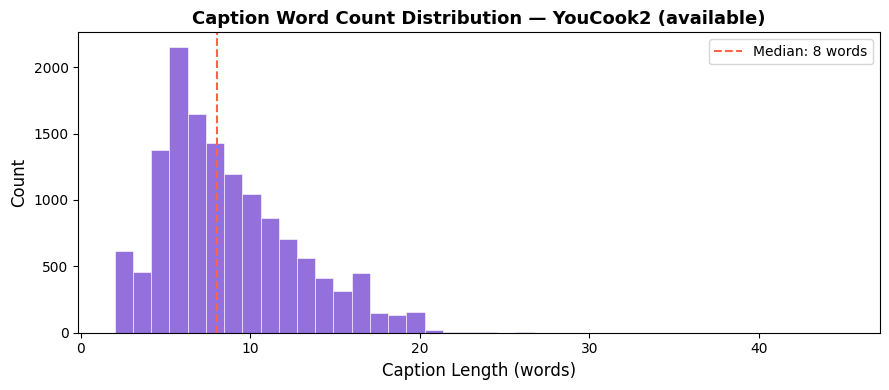


Sample very-short captions:


,segment_id,caption
894,Tf-gY_-pT1U_001,boil potatoes
1231,2Rn2tM9Rgg8_008,add eggs
2097,A4pTxrrBtMU_000,preheat grill
2155,Cgyi5kaU7Qc_005,add onions
2156,Cgyi5kaU7Qc_006,add vegetables


In [14]:
import matplotlib.pyplot as plt

df_avail['caption_len'] = df_avail['caption'].fillna('').str.split().str.len()

print("=" * 55)
print("  CAPTION WORD-COUNT STATISTICS")
print("=" * 55)
print(df_avail['caption_len'].describe(percentiles=[.05, .25, .5, .75, .95]).to_string())

very_short = (df_avail['caption_len'] < 3).sum()
very_long  = (df_avail['caption_len'] > 30).sum()
null_cap   = df_avail['caption'].isna().sum()
duplicates = df_avail.duplicated(subset=['caption'], keep=False).sum()

print(f"\n  Null captions             : {null_cap:,}")
print(f"  Very short  (< 3 words)   : {very_short:,}")
print(f"  Very long   (> 30 words)  : {very_long:,}")
print(f"  Duplicate captions        : {duplicates:,}  (flagged, not removed)")

# Histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df_avail['caption_len'], bins=40, color='mediumpurple', edgecolor='white', linewidth=0.4)
ax.axvline(df_avail['caption_len'].median(), color='tomato', linestyle='--',
           label=f"Median: {df_avail['caption_len'].median():.0f} words")
ax.set_xlabel('Caption Length (words)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('Caption Word Count Distribution — YouCook2 (available)', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

if very_short > 0:
    print("\nSample very-short captions:")
    display(df_avail[df_avail['caption_len'] < 3][['segment_id', 'caption']].head(5))


## P8 · Split Integrity Check
Verifies there is zero video-ID overlap between train and validation splits.

In [15]:
train_ids = set(df_avail[df_avail['subset'] == 'training']['video_id'])
val_ids   = set(df_avail[df_avail['subset'] == 'validation']['video_id'])
overlap   = train_ids & val_ids

print("=" * 55)
print("  SPLIT INTEGRITY CHECK")
print("=" * 55)
print(f"  Training videos    : {len(train_ids):,}")
print(f"  Validation videos  : {len(val_ids):,}")
print(f"  Overlap (must=0)   : {len(overlap)}")

if len(overlap) == 0:
    print("\n  ✓  No video IDs appear in both splits. Split is clean.")
else:
    print(f"\n  ✗  WARNING — {len(overlap)} video IDs appear in BOTH splits!")
    print("     Overlapping IDs:", list(overlap)[:10])


  SPLIT INTEGRITY CHECK
  Training videos    : 1,322
  Validation videos  : 452
  Overlap (must=0)   : 0

  ✓  No video IDs appear in both splits. Split is clean.


## P9 · Printable One-Page Summary
Produces a single text block you can paste into slides or share with your mentor.

In [16]:
n_success = (report['status'] == 'success').sum()
n_skipped = (report['status'] == 'skipped').sum()
n_failed  = (report['status'] == 'failed').sum()
n_avail   = n_success + n_skipped

train_segs = (df_avail['subset'] == 'training').sum()
val_segs   = (df_avail['subset'] == 'validation').sum()

sep = '=' * 60
summary = f"""
{sep}
  YouCook2 — Dataset Preparation Summary
{sep}

  ANNOTATION SET
    Total segments (all)    : {len(df_all):,}
    Unique videos  (all)    : {df_all['video_id'].nunique():,}
    Training segments       : {(df_all['subset']=='training').sum():,}
    Validation segments     : {(df_all['subset']=='validation').sum():,}

  DOWNLOAD RESULTS
    Downloaded (new)        : {n_success:,}
    Already on disk         : {n_skipped:,}
    Failed (unavailable)    : {n_failed:,}  ({100*n_failed/len(report):.1f}% — expected)
    Available total         : {n_avail:,}  ({100*n_avail/len(report):.1f}% of dataset)

  AVAILABLE SEGMENTS
    Total                   : {len(df_avail):,}
    Training                : {train_segs:,}
    Validation              : {val_segs:,}
    Unique recipe types     : {df_avail['recipe_type'].nunique()}
    Avg duration            : {df_avail['duration'].mean():.1f}s
    Median duration         : {df_avail['duration'].median():.1f}s
    Avg segments / video    : {df_avail.groupby('video_id').size().mean():.1f}
    Avg caption length      : {df_avail['caption'].str.split().str.len().mean():.1f} words

  SPLIT INTEGRITY
    Train/val overlap       : {len(train_ids & val_ids)} video IDs  ({'✓ Clean' if len(train_ids & val_ids)==0 else '✗ OVERLAP DETECTED'})

{sep}
  Next step → Notebook 3: verb extraction and caption masking
{sep}
"""

print(summary)

# Save to file
with open(os.path.join(ANN_DIR, 'mentor_summary.txt'), 'w') as f:
    f.write(summary)
print(f"Saved → {os.path.join(ANN_DIR, 'mentor_summary.txt')}")



  YouCook2 — Dataset Preparation Summary

  ANNOTATION SET
    Total segments (all)    : 13,829
    Unique videos  (all)    : 1,790
    Training segments       : 10,337
    Validation segments     : 3,492

  DOWNLOAD RESULTS
    Downloaded (new)        : 1,774
    Already on disk         : 0
    Failed (unavailable)    : 16  (0.9% — expected)
    Available total         : 1,774  (99.1% of dataset)

  AVAILABLE SEGMENTS
    Total                   : 13,716
    Training                : 10,259
    Validation              : 3,457
    Unique recipe types     : 89
    Avg duration            : 19.6s
    Median duration         : 14.0s
    Avg segments / video    : 7.7
    Avg caption length      : 8.8 words

  SPLIT INTEGRITY
    Train/val overlap       : 0 video IDs  (✓ Clean)

  Next step → Notebook 3: verb extraction and caption masking

Saved → /home/ubuntu/youcook2-videos/annotations/mentor_summary.txt
